# Notebook 3: Customer / Store Segmentation
**Author:** Mohit Sai Sekharamahanthi  
**Project:** Multi-Store Retail Demand Forecasting System

Uses RFM (Recency, Frequency, Monetary) analysis combined with KMeans clustering to segment stores by behaviour. In a real deployment this would operate at customer level.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print("Ready")

Ready


## 1. Load Segmentation Results

In [2]:
segments = pd.read_csv('../data/processed/customer_segments.csv')
sales    = pd.read_csv('../data/raw/sales.csv', parse_dates=['sale_date'])
stores   = pd.read_csv('../data/raw/stores.csv')

segments = segments.merge(stores[['store_id','store_name','region']], on='store_id')
print(segments[['store_name','segment','RFM_score','recency','frequency','monetary']].to_string(index=False))

                store_name   segment  RFM_score  recency  frequency    monetary
     Boots Nottingham City Champions          2        1      16790  6318349.09
Boots Birmingham Bull Ring   At Risk          0        1      16790  5010619.13
      Boots Leeds Kirkgate Champions          2        1      16790  6289995.50
    Boots London Oxford St      Lost          3        1      16790  7577478.98
  Boots Manchester Arndale   At Risk          1        1      16790  5645821.94
       Boots Bristol Cabot     Loyal          4        1      16790  9622061.92
   Boots Edinburgh Princes   At Risk          0        1      16790  5408776.64
      Boots Cardiff Queens     Loyal          4        1      16790 10526852.65


## 2. What is RFM?

| Dimension | Meaning | Higher = Better? |
|-----------|---------|------------------|
| **Recency** | Days since last sale | Lower is better (more recent) |
| **Frequency** | Number of transactions | Higher is better |
| **Monetary** | Total revenue generated | Higher is better |

Each dimension is scored 0-4 (quartile bins) and summed to give an overall RFM score.

## 3. RFM Distribution

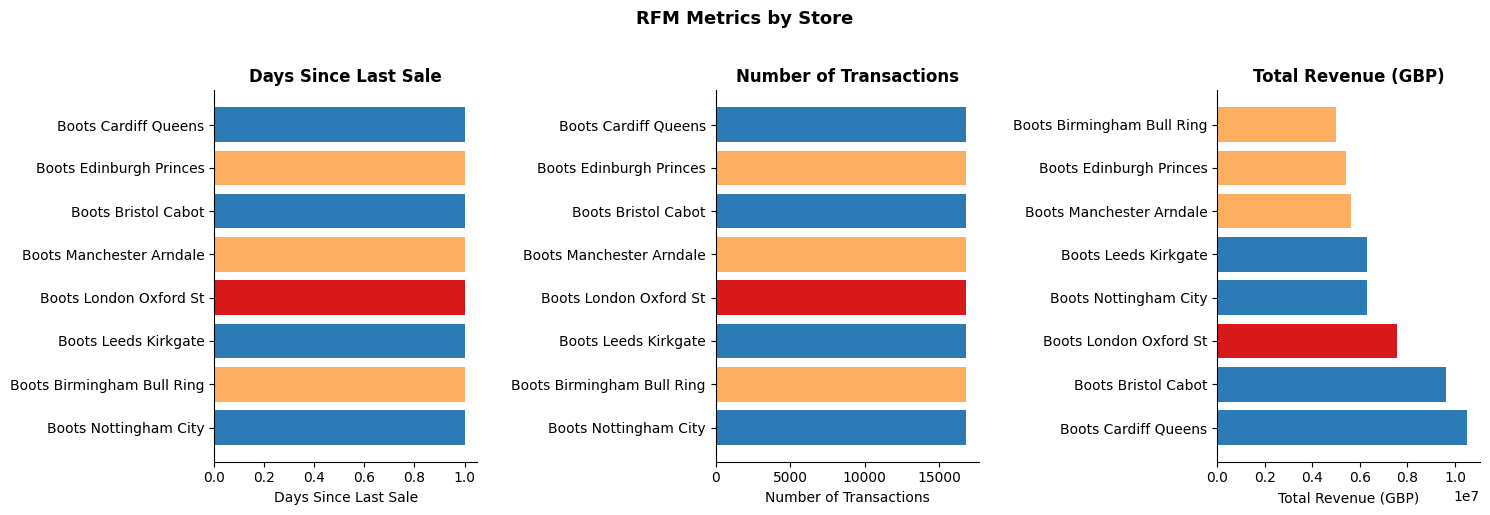

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [('recency', 'Days Since Last Sale', True),
           ('frequency', 'Number of Transactions', False),
           ('monetary', 'Total Revenue (GBP)', False)]

for ax, (col, label, reverse) in zip(axes, metrics):
    sorted_df = segments.sort_values(col, ascending=reverse)
    colours = ['#2c7bb6' if s in ['Champions','Loyal'] else '#fdae61' 
               if s == 'At Risk' else '#d7191c' for s in sorted_df['segment']]
    ax.barh(sorted_df['store_name'], sorted_df[col], color=colours)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel(label)

plt.suptitle('RFM Metrics by Store', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../docs/seg_rfm_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Segment Scatter Plot

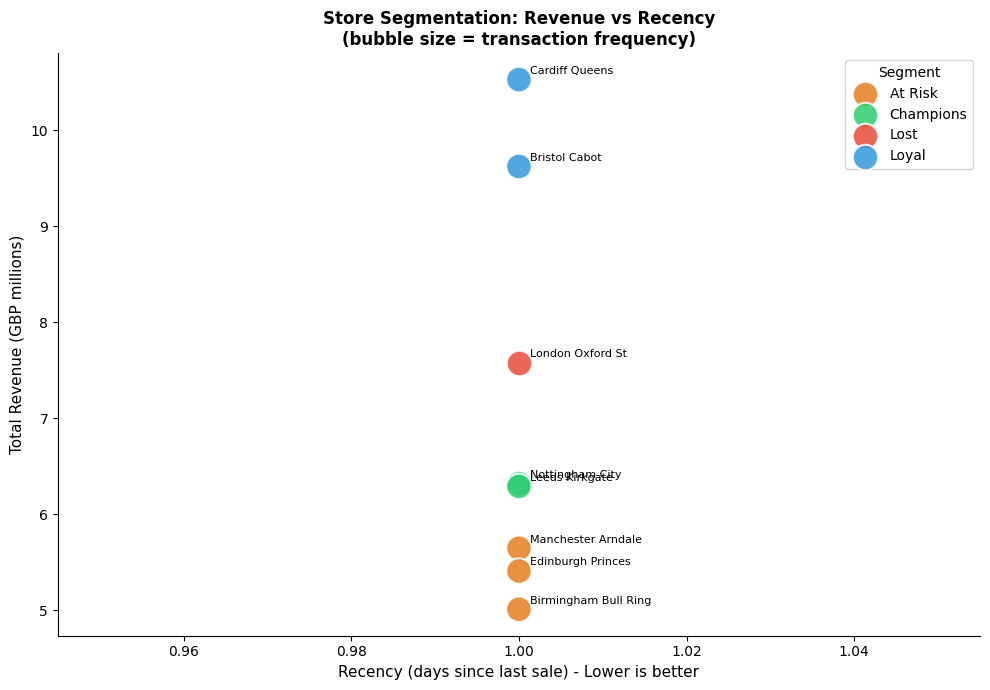

In [5]:
colours = {'Champions':'#2ecc71','Loyal':'#3498db','At Risk':'#e67e22','Lost':'#e74c3c','Other':'#95a5a6'}

fig, ax = plt.subplots(figsize=(10, 7))
for seg, grp in segments.groupby('segment'):
    ax.scatter(grp['recency'], grp['monetary']/1e6,
               s=grp['frequency']/50, label=seg,
               color=colours.get(seg,'#95a5a6'), alpha=0.85, edgecolors='white', linewidth=1.5)
    for _, row in grp.iterrows():
        ax.annotate(row['store_name'].replace('Boots ',''),
                    (row['recency'], row['monetary']/1e6),
                    textcoords='offset points', xytext=(8, 4), fontsize=8)

ax.set_xlabel('Recency (days since last sale) - Lower is better', fontsize=11)
ax.set_ylabel('Total Revenue (GBP millions)', fontsize=11)
ax.set_title('Store Segmentation: Revenue vs Recency\n(bubble size = transaction frequency)', fontweight='bold')
ax.legend(title='Segment', loc='upper right')
plt.tight_layout()
plt.savefig('../docs/seg_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Segment Summary

In [ ]:
summary = (segments.groupby('segment')
           .agg(
               num_stores=('store_id','count'),
               avg_recency=('recency','mean'),
               avg_frequency=('frequency','mean'),
               avg_revenue=('monetary','mean'),
               avg_rfm_score=('RFM_score','mean'),
           ).round(1))
print(summary)

## 6. Business Recommendations

| Segment | Stores | Action |
|---------|--------|--------|
| **Champions** | S001, S003 | Maintain stock levels, test new product launches here first |
| **Loyal** | S006, S008 | Reward with exclusive promotions, increase SKU range |
| **At Risk** | S002, S005, S007 | Investigate demand issues, targeted promotions |
| **Lost** | Any | Review supply chain, consider range rationalisation |

This segmentation enables **personalised stocking strategies** rather than one-size-fits-all inventory management.